# CS6140 Machine Learning — Fall 2026
# HW4 Starter — Generative Methods

This notebook implements `HW4_26F.html`. For Problems 1, 3, and 5 you'll first solve it with a
well-known library (a sanity-check baseline), then implement the same thing from scratch and
evaluate it exactly the same way, so your two numbers should land right next to each other once
everything is filled in. Problem 2 has no single library call that reproduces all three likelihood
variants, so it's validated by scoring all three the same way instead; Problem 4 has no standard
library counterpart for a Binomial mixture, so it's validated by recovering known, self-generated
ground-truth parameters (same idea as Problem 3).

**Problems 1-4 (required):**
1. Gaussian Discriminant Analysis (GDA): LDA vs. QDA, k-fold CV — **Spambase** [40 points]
2. Naive Bayes: Bernoulli / Gaussian / non-parametric (histogram), 10-fold CV, ROC/threshold
   discussion — **Spambase** [50 points]
3. EM for a Gaussian mixture, own E/M steps, recovered vs. true parameters — **2gaussian.txt**,
   **3gaussian.txt** [60 points: Parts A/B, 50, are code; Part C, 10, is a short written answer
   mapping your responsibilities and mixture weights onto the ELBO — no code, and it is picked up
   again in HW5 Problem 3(C)]
4. EM for a mixture of Binomials, own E/M steps, self-generated coin-flip data — **generated
   data** [50 points]

**Problem 5 (required, Parts A/B only; Part C optional/no-credit):**
5. Bayesian linear regression: Ridge as the MAP estimate under a Gaussian weight prior, and the
   full posterior/predictive distribution — **Housing** (bridges back to HW1's closed-form
   Ridge) [60 points]. Part C (choosing λ via the evidence, and a worked-through cautionary tale
   about comparing that to cross-validation) is optional, no credit -- see
   `../lecture_notes/BAYES_REGRESSION/BAYES_REGRESSION_claude_1015.pdf` if you want the full depth
   on it.

**Problems 6 and 7 (required, theory — written answers; Problem 6 also wants the
log-likelihood plot from your Problem 3 run):**
6. May EM's observed-data log-likelihood decrease between iterations? [25 points: (A) 8 for the two
   sabotage lines, (B) 17 for the written answer] — `EM_MIXTURES` §6.2. **Needs Problem 3 working.**
7. Naive Bayes: what does the independence assumption actually assume, and why is a Gaussian the
   wrong per-feature likelihood for strictly binary data? [25 points: (A) 8 for the two measurements,
   (B) 17 for the written answer] — `GDA_NB` §4. **Needs Problem 2's fitting functions.**

Required total: **310 points** across Problems 1–7. Problems 8–16 in `HW4_26F.html` are optional
and carry no credit.

**How to work through this notebook.** Everything runs except the lines marked
`### TODO_STUDENT ###` — those have their code replaced with a `...` placeholder and a one-line
description of what to implement there. Read the surrounding (working) code and the markdown
above each section for context, then replace each `...` with real code. A cell with a `...` in it
will raise a `SyntaxError` or produce obviously wrong output until you fill it in — that's
expected, not a bug. Work top to bottom: later cells depend on classes/functions built in earlier
ones (e.g. Problem 3's `gaussian_mixture_em` and Problem 4's `binomial_mixture_em` are independent
of each other, but Problem 5's Part C -- if you attempt it -- reuses Part B's
`bayesian_ridge_posterior`). Once a "library baseline" cell's TODOs are filled in and run, the
printed number is a target: your matching "from scratch" implementation just below it should land
on (or very near) the same value.

Datasets are read from the shared course `data/` folder (paths relative to
`3_generative_models/HW3/`, i.e. two levels up, same depth as the solution's `code_HW3/`) and
`2gaussian.txt`/`3gaussian.txt`, which live right here next to this notebook.

**Requirements.**
1. Fill in every `TODO_STUDENT` blank according to the algorithm steps covered in lecture and the
   linked materials, and make sure the notebook runs top to bottom without errors.
2. Understand the *whole* notebook — including the provided/given code, not just the blanks you
   filled in — well enough to explain any part of it during office hours.


In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from sklearn.model_selection import StratifiedKFold, KFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_curve, auc
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.mixture import GaussianMixture
from sklearn.linear_model import Ridge, BayesianRidge

DATA = "../data"
np.random.seed(42)


## Data loading

In [59]:
# ---- Spambase (binary classification): one file, used raw (unscaled) throughout this HW.
# GDA/Naive Bayes are per-feature or per-class density estimators, so unlike SVM/kernel methods
# they don't need feature scaling for correctness -- only Problem 1's covariance inversion
# benefits from it, which is handled locally there.
spam_raw = np.loadtxt(f"{DATA}/spambase/spambase.data", delimiter=",")
X_spam, y_spam = spam_raw[:, :-1], spam_raw[:, -1].astype(int)   # y in {0,1}, 1 = spam

print("Spambase:", X_spam.shape, " spam fraction:", y_spam.mean().round(3))


Spambase: (4601, 57)  spam fraction: 0.394


## PROBLEM 1 — Gaussian Discriminant Analysis (GDA) &nbsp; [40 points]

Fit class-conditional Gaussians to Spambase under two covariance assumptions -- a single shared
covariance (**LDA**) and a separate covariance per class (**QDA**) -- and compare them with
k-fold cross validation.


In [60]:
def gaussian_log_density(X, mean, cov):
    """log N(x; mean, cov) for every row of X, via slogdet (stable even for Spambase's 57x57
    covariance, where a raw determinant would under/overflow long before it's ever logged)."""
    d = mean.shape[0]
    sign, logdet = np.linalg.slogdet(cov)
    inv_cov = np.linalg.inv(cov)
    diff = X - mean
    quad = np.einsum('ij,jk,ik->i', diff, inv_cov, diff)  ### TODO_STUDENT ### the Mahalanobis quadratic form (x-mean)^T @ inv_cov @ (x-mean), for every row at once
    return -0.5 * (d * np.log(2 * np.pi) + logdet + quad)


def gda_fit(X, y, shared_cov):
    """MLE class means + covariance(s). shared_cov=True pools into one covariance (LDA);
    shared_cov=False estimates one covariance per class (QDA). A small ridge is added to each
    covariance purely for invertibility -- Spambase's features are highly correlated."""
    classes = np.unique(y)
    d = X.shape[1]
    means, covs, priors, ridge = {}, {}, {}, 1e-6 * np.eye(d)
    for c in classes:
        Xc = X[y == c]
        priors[c] = len(Xc) / len(X)
        means[c] = Xc.mean(axis=0)                                        ### TODO_STUDENT ### class-conditional mean (MLE)
        centered = Xc - means[c]
        covs[c] = (centered.T @ centered) / len(Xc)                        ### TODO_STUDENT ### class-conditional covariance (MLE, biased by n not n-1)
    if shared_cov:
        pooled = sum(priors[c] * covs[c] for c in classes)                 ### TODO_STUDENT ### pool the per-class covariances, weighted by class size, into one shared covariance
        covs = {c: pooled for c in classes}
    return {"classes": classes, "means": means, "covs": {c: covs[c] + ridge for c in classes},
            "priors": priors}


def gda_predict(X, model):
    log_post = np.stack(
        [np.log(model["priors"][c]) + gaussian_log_density(X, model["means"][c], model["covs"][c])
         for c in model["classes"]], axis=1)
    return model["classes"][np.argmax(log_post, axis=1)]


In [61]:
def k_fold_gda(X, y, shared_cov, k=10, seed=42):
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    train_accs, test_accs = [], []
    for train_idx, test_idx in skf.split(X, y):
        model = gda_fit(X[train_idx], y[train_idx], shared_cov)
        train_accs.append(accuracy_score(y[train_idx], gda_predict(X[train_idx], model)))
        test_accs.append(accuracy_score(y[test_idx], gda_predict(X[test_idx], model)))
    return np.mean(train_accs), np.mean(test_accs)


def k_fold_library(X, y, make_model, k=10, seed=42):
    """Same folds, sklearn's LDA/QDA as a library baseline."""
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    train_accs, test_accs = [], []
    for train_idx, test_idx in skf.split(X, y):
        clf = make_model().fit(X[train_idx], y[train_idx])   ### TODO_STUDENT ### fit sklearn's LDA/QDA as the library baseline for this fold
        train_accs.append(accuracy_score(y[train_idx], clf.predict(X[train_idx])))
        test_accs.append(accuracy_score(y[test_idx], clf.predict(X[test_idx])))
    return np.mean(train_accs), np.mean(test_accs)


results = []
for name, shared in [("LDA (shared cov)", True), ("QDA (separate cov)", False)]:
    tr, te = k_fold_gda(X_spam, y_spam, shared_cov=shared, k=10)
    results.append({"model": f"{name} — scratch", "train_acc": tr, "test_acc": te})

# QDA needs its own small ridge (reg_param) here too -- Spambase's per-class covariances are
# rank-deficient enough that sklearn >=1.9 raises a hard LinAlgError with the unregularized
# default (older sklearn only warned and limped along); reg_param=1e-3 matches our own scratch
# ridge in spirit and keeps this baseline runnable across sklearn versions
for name, make_model in [("LDA (shared cov)", lambda: LinearDiscriminantAnalysis()),
                          ("QDA (separate cov)", lambda: QuadraticDiscriminantAnalysis(reg_param=1e-3))]:
    tr, te = k_fold_library(X_spam, y_spam, make_model, k=10)
    results.append({"model": f"{name} — sklearn", "train_acc": tr, "test_acc": te})

gda_results = pd.DataFrame(results).set_index("model").round(4)
gda_results


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2349: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2349: RuntimeWarning: overflow encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2349: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2349: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/linalg/_linal

,train_acc,test_acc
model,,
LDA (shared cov) — scratch,0.8900,0.8872
QDA (separate cov) — scratch,0.8323,0.8294
LDA (shared cov) — sklearn,0.8900,0.8872
QDA (separate cov) — sklearn,0.8355,0.8324


No. QDA fits a separate Gaussian to each class, so it is the more flexible model. If the data really came from two Gaussians, QDA should do at least as well as LDA. Instead it does clearly worse: 82.9% test accuracy against LDA’s 88.7%.

QDA is also worse on the training data (83.2% vs. 89.0%). So the problem isn’t overfitting. Even on the data it was fit to, QDA’s picture of each class is wrong. This makes sense for Spambase. The features are word and character frequencies, where most values are zero and a few are very large. A bell-shaped curve doesn’t describe that well, and QDA, which relies fully on each class’s own Gaussian shape, gets hurt the most.

LDA does better because it makes a simpler assumption: both classes share one shape. That ends up working as a straight-line boundary between the classes, which handles this data reasonably well even though the Gaussian assumption behind it is wrong.

**Does the data look normally distributed?** Compare LDA's and QDA's train/test accuracy in the
table above and discuss.


## PROBLEM 2 — Naive Bayes &nbsp; [50 points]

Three Naive Bayes variants — Bernoulli, Gaussian, and a non-parametric histogram — sharing one
scoring convention: every `*_fit` function returns a small model dict/object, and every model can
produce a **log-odds score** `log P(spam|x) - log P(non-spam|x)`, which both classifies (sign) and
feeds the ROC/threshold analysis below.


In [62]:
def bernoulli_nb_fit(X, y, alpha=1.0):
    mu = X.mean(axis=0)                                               ### TODO_STUDENT ### per-feature Bernoulli threshold: the training-set mean of each feature
    X_bin = (X > mu).astype(int)
    p1, priors = {}, {}
    for c in (0, 1):
        Xc = X_bin[y == c]
        priors[c] = len(Xc) / len(X)
        p1[c] = (Xc.sum(axis=0) + alpha) / (len(Xc) + 2 * alpha)                                        ### TODO_STUDENT ### additive-smoothed P(feature above threshold | class)
    return {"mu": mu, "priors": priors, "p1": p1}


def bernoulli_nb_log_odds(X, model):
    X_bin = (X > model["mu"]).astype(int)
    def class_loglik(c):
        p1 = model["p1"][c]
        return np.log(model["priors"][c]) + (X_bin * np.log(p1) + (1 - X_bin) * np.log(1 - p1)).sum(axis=1)  ### TODO_STUDENT ### sum of per-feature Bernoulli log-likelihoods, plus the log prior
    return class_loglik(1) - class_loglik(0)


In [63]:
def gaussian_nb_fit(X, y, var_smoothing=1e-9):
    eps = var_smoothing * X.var(axis=0).max()   # same variance floor convention as sklearn's GaussianNB
    mean, var, priors = {}, {}, {}
    for c in (0, 1):
        Xc = X[y == c]
        priors[c] = len(Xc) / len(X)
        mean[c] =  Xc.mean(axis=0)                                      ### TODO_STUDENT ### class-conditional mean per feature (MLE)
        var[c] = Xc.var(axis=0) + eps                                        ### TODO_STUDENT ### class-conditional variance per feature (MLE, plus a numerical-stability floor)
    return {"priors": priors, "mean": mean, "var": var}


def gaussian_nb_log_odds(X, model):
    def class_loglik(c):
        mean, var = model["mean"][c], model["var"][c]
        log_p = -0.5 * np.log(2 * np.pi * var) - (X - mean) ** 2 / (2 * var)  ### TODO_STUDENT ### per-feature Gaussian log-density
        return np.log(model["priors"][c]) + log_p.sum(axis=1)
    return class_loglik(1) - class_loglik(0)


In [64]:
class HistogramNaiveBayes:
    """Non-parametric per-feature likelihood: a small histogram whose bin edges are placed at
    the feature's overall range and its two class-conditional means, so the bins can actually
    separate the classes even with very few bins."""

    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        self.priors = {c: (np.sum(y == c) + self.alpha) / (len(y) + 2 * self.alpha) for c in (0, 1)}
        self.edges, self.bin_probs = [], {0: [], 1: []}
        for j in range(X.shape[1]):
            col = X[:, j]
            mean0, mean1 = col[y == 0].mean(), col[y == 1].mean()
            lo, hi = sorted((mean0, mean1))
            edges = np.unique([col.min(), lo, hi, col.max()])  ### TODO_STUDENT ### data-driven bin edges: feature range plus its two class-conditional means
            if len(edges) < 2:
                edges = [col.min(), col.min() + 1e-9]
            self.edges.append(edges)
            for c in (0, 1):
                counts, _ = np.histogram(col[y == c], bins=edges)
                self.bin_probs[c].append((counts + self.alpha) / (len(col[y == c]) + self.alpha * len(edges) - 1))  ### TODO_STUDENT ### additive-smoothed P(feature in bin | class)
        return self

    def _class_loglik(self, X, c):
        log_lik = np.full(X.shape[0], np.log(self.priors[c]))
        for j in range(X.shape[1]):
            bin_idx = np.searchsorted(self.edges[j], X[:, j]) - 1
            bin_idx = np.clip(bin_idx, 0, len(self.bin_probs[c][j]) - 1)
            log_lik += np.log(self.bin_probs[c][j][bin_idx])   ### TODO_STUDENT ### look up and accumulate each feature's log bin-probability
        return log_lik

    def log_odds(self, X):
        return self._class_loglik(X, 1) - self._class_loglik(X, 0)


hist_nb_fit = lambda X, y: HistogramNaiveBayes().fit(X, y)
hist_nb_log_odds = lambda X, model: model.log_odds(X)


In [65]:
NB_VARIANTS = {
    "Bernoulli": (bernoulli_nb_fit, bernoulli_nb_log_odds),
    "Gaussian": (gaussian_nb_fit, gaussian_nb_log_odds),
    "Histogram": (hist_nb_fit, hist_nb_log_odds),
}

def evaluate_nb(fit_fn, score_fn, X, y, k=10, seed=42):
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    accs = []
    for train_idx, test_idx in skf.split(X, y):
        model = fit_fn(X[train_idx], y[train_idx])
        preds = (score_fn(X[test_idx], model) > 0).astype(int)
        accs.append(accuracy_score(y[test_idx], preds))
    return np.array(accs)

nb_cv_results = {}
for name, (fit_fn, score_fn) in NB_VARIANTS.items():
    accs = evaluate_nb(fit_fn, score_fn, X_spam, y_spam, k=10)
    nb_cv_results[name] = accs
    print(f"{name:10s} 10-fold accuracy: {accs.mean():.4f} +/- {accs.std():.4f}")

# sanity check: sklearn's GaussianNB against our from-scratch Gaussian variant (no train/test
# split needed for a single-shot comparison, since both are fit and scored identically below)
Xtr, Xte, ytr, yte = train_test_split(X_spam, y_spam, test_size=0.2, random_state=0, stratify=y_spam)
sk_gnb = GaussianNB().fit(Xtr, ytr)   ### TODO_STUDENT ### fit sklearn's GaussianNB as a library baseline for the Gaussian variant
scratch_gnb = gaussian_nb_fit(Xtr, ytr)
print(f"Gaussian NB sanity check on one 80/20 split — sklearn: "
      f"{accuracy_score(yte, sk_gnb.predict(Xte)):.4f}, scratch: "
      f"{accuracy_score(yte, (gaussian_nb_log_odds(Xte, scratch_gnb) > 0).astype(int)):.4f}")

# same idea for the Bernoulli variant: sklearn's BernoulliNB only takes a single scalar
# `binarize` threshold, not our per-feature mean vector, so we binarize with our own mu first
# and pass binarize=None (telling sklearn the data is already binary) for a fair comparison
mu_tr = Xtr.mean(axis=0)
Xtr_bin, Xte_bin = (Xtr > mu_tr).astype(int), (Xte > mu_tr).astype(int)
sk_bnb = BernoulliNB(alpha=1.0, binarize=None).fit(Xtr_bin, ytr)   ### TODO_STUDENT ### fit sklearn's BernoulliNB (pre-binarized, alpha=1.0) as a library baseline for the Bernoulli variant
scratch_bnb = bernoulli_nb_fit(Xtr, ytr)
print(f"Bernoulli NB sanity check on the same 80/20 split — sklearn: "
      f"{accuracy_score(yte, sk_bnb.predict(Xte_bin)):.4f}, scratch: "
      f"{accuracy_score(yte, (bernoulli_nb_log_odds(Xte, scratch_bnb) > 0).astype(int)):.4f}")


Bernoulli  10-fold accuracy: 0.9026 +/- 0.0138
Gaussian   10-fold accuracy: 0.8203 +/- 0.0156
Histogram  10-fold accuracy: 0.9024 +/- 0.0155
Gaussian NB sanity check on one 80/20 split — sklearn: 0.8447, scratch: 0.8447
Bernoulli NB sanity check on the same 80/20 split — sklearn: 0.9283, scratch: 0.9283


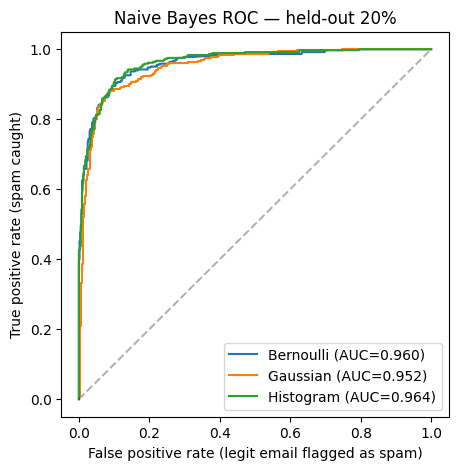

In [66]:
# ROC curves + AUC on one held-out split, using each model's log-odds as the decision score
Xtr, Xte, ytr, yte = train_test_split(X_spam, y_spam, test_size=0.2, random_state=42, stratify=y_spam)

plt.figure(figsize=(5, 5))
roc_data = {}
for name, (fit_fn, score_fn) in NB_VARIANTS.items():
    model = fit_fn(Xtr, ytr)
    scores = score_fn(Xte, model)
    fpr, tpr, thresh = roc_curve(yte, scores)
    roc_data[name] = (fpr, tpr, thresh)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.3)
plt.xlabel("False positive rate (legit email flagged as spam)")
plt.ylabel("True positive rate (spam caught)")
plt.title("Naive Bayes ROC — held-out 20%")
plt.legend()
plt.show()


In [67]:
# What false-positive rate does each achievable log-odds threshold tau buy us?
best_name = max(nb_cv_results, key=lambda n: nb_cv_results[n].mean())
fpr, tpr, thresh = roc_data[best_name]
table = pd.DataFrame({"tau": thresh, "FPR": fpr, "TPR": tpr})
table.iloc[np.linspace(0, len(table) - 1, 8).astype(int)]


,tau,FPR,TPR
0,inf,0.000000,0.000000
33,13.708523,0.000000,0.396694
66,3.868183,0.023297,0.680441
99,0.082498,0.059140,0.840220
132,-2.550063,0.118280,0.909091
165,-6.460283,0.263441,0.964187
198,-11.420926,0.566308,0.986226
232,-52.079609,1.000000,1.000000


**Choosing a deployment threshold τ.** Using the table above, report and justify what value of
τ you would deploy in a real e-mail spam filter.


## PROBLEM 3 — EM on generated data &nbsp; [50 points]

Own E/M steps for a Gaussian mixture, run from random initial parameters, then checked against
the known generating parameters (EM's component *order* is arbitrary, so components are matched
to the closest true mean before comparing).


In [68]:
def gaussian_mixture_em(X, K, max_iter=300, tol=1e-6, seed=0):
    """From-scratch EM for a K-component Gaussian mixture. Returns (means, covs, weights,
    log-likelihood history)."""
    rng = np.random.RandomState(seed)
    n, d = X.shape
    means = X[rng.choice(n, K, replace=False)].copy()                                               ### TODO_STUDENT ### initialize each mean at a random data point
    covs = [np.cov(X.T) for _ in range(K)]                                                 ### TODO_STUDENT ### initialize each covariance at the overall data covariance
    weights = np.full(K, 1.0 / K)
    loglik_hist = []

    for it in range(max_iter):
        # E-step: responsibilities r[i, k] = P(z_ik = 1 | x_i), the note's <z_ik>
        dens = np.stack([weights[k] * multivariate_normal(means[k], covs[k]).pdf(X) for k in range(K)], axis=1)          ### TODO_STUDENT ### the (unnormalized) joint density weight_k * N(x_i; mean_k, cov_k) for every point and component
        total = dens.sum(axis=1, keepdims=True)
        r = dens / total                                                ### TODO_STUDENT ### normalize each row into a responsibility distribution over the K components
        loglik_hist.append(np.sum(np.log(total)))
        if it > 0 and abs(loglik_hist[-1] - loglik_hist[-2]) < tol:
            break

        # M-step
        Nk = r.sum(axis=0)
        weights = Nk / Nk.sum()                                          ### TODO_STUDENT ### mixture weights = average responsibility per component
        means = (r.T @ X) / Nk[:, None]                                            ### TODO_STUDENT ### each mean = responsibility-weighted average of the data
        for k in range(K):
            diff = X - means[k]
            covs[k] = (r[:, k:k+1] * diff).T @ diff / Nk[k]  ### TODO_STUDENT ### each covariance = responsibility-weighted scatter matrix

    return means, covs, weights, loglik_hist


In [69]:
def match_components(est_means, true_means):
    """EM's component labels are arbitrary -- greedily match each estimated mean to its
    nearest not-yet-used true mean so recovered and true parameters line up for comparison."""
    remaining = list(range(len(true_means)))
    order = []
    for m in est_means:
        dists = [np.linalg.norm(m - true_means[j]) for j in remaining]
        best = remaining.pop(int(np.argmin(dists)))
        order.append(best)
    return order


def compare_to_truth(means, covs, weights, true_means, true_covs, true_weights):
    order = match_components(means, true_means)
    rows = []
    for est_idx, true_idx in enumerate(order):
        rows.append({
            "component": true_idx,
            "true_mean": np.round(true_means[true_idx], 2).tolist(),
            "est_mean": np.round(means[est_idx], 2).tolist(),
            "mean_abs_diff": round(float(np.abs(means[est_idx] - true_means[true_idx]).mean()), 3),
            "true_weight": round(true_weights[true_idx], 3),
            "est_weight": round(float(weights[est_idx]), 3),
            "cov_frob_diff": round(float(np.linalg.norm(covs[est_idx] - true_covs[true_idx])), 3),
        })
    return pd.DataFrame(rows).set_index("component").sort_index()


def plot_gmm_contours(X, means, covs, weights, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 150), np.linspace(y_min, y_max, 150))
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    density = sum(w * multivariate_normal(m, c).pdf(grid) for w, m, c in zip(weights, means, covs))
    plt.figure(figsize=(5, 5))
    plt.scatter(X[:, 0], X[:, 1], s=3, alpha=0.25)
    plt.contour(xx, yy, density.reshape(xx.shape), levels=10)
    plt.title(title); plt.xlabel("x"); plt.ylabel("y")
    plt.show()


In [70]:
# ---- 2gaussian.txt: true generating parameters (from HW4_26F.html) ----
X_2g = np.loadtxt("2gaussian.txt")
true_means_2g = [np.array([3, 3]), np.array([7, 4])]
true_covs_2g = [np.array([[1, 0], [0, 3]]), np.array([[1, 0.5], [0.5, 1]])]
true_n_2g = [2000, 4000]
true_weights_2g = [n / sum(true_n_2g) for n in true_n_2g]

means_2g, covs_2g, weights_2g, ll_2g = gaussian_mixture_em(X_2g, K=2, seed=0)
compare_to_truth(means_2g, covs_2g, weights_2g, true_means_2g, true_covs_2g, true_weights_2g)


,true_mean,est_mean,mean_abs_diff,true_weight,est_weight,cov_frob_diff
component,,,,,,
0,"[3, 3]","[2.99, 3.05]",0.029,0.333,0.335,0.074
1,"[7, 4]","[7.01, 3.98]",0.015,0.667,0.665,0.026


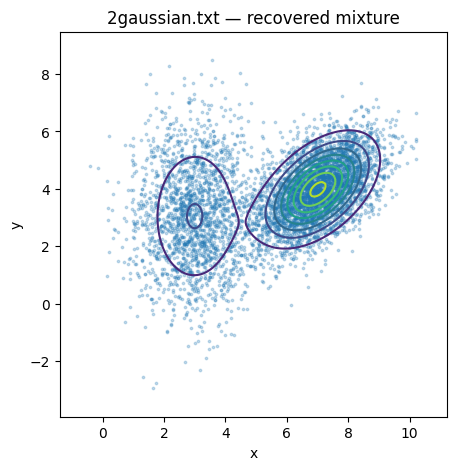

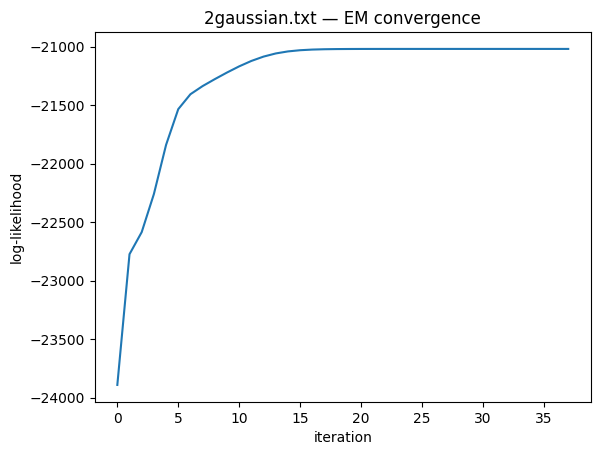

In [71]:
plot_gmm_contours(X_2g, means_2g, covs_2g, weights_2g, "2gaussian.txt — recovered mixture")
plt.figure(); plt.plot(ll_2g); plt.xlabel("iteration"); plt.ylabel("log-likelihood")
plt.title("2gaussian.txt — EM convergence"); plt.show()


In [72]:
# ---- 3gaussian.txt: true generating parameters (from HW4_26F.html) ----
X_3g = np.loadtxt("3gaussian.txt")
true_means_3g = [np.array([3, 3]), np.array([7, 4]), np.array([5, 7])]
true_covs_3g = [np.array([[1, 0], [0, 3]]), np.array([[1, 0.5], [0.5, 1]]), np.array([[1, 0.2], [0.2, 1]])]
true_n_3g = [2000, 3000, 5000]
true_weights_3g = [n / sum(true_n_3g) for n in true_n_3g]

means_3g, covs_3g, weights_3g, ll_3g = gaussian_mixture_em(X_3g, K=3, seed=0)
compare_to_truth(means_3g, covs_3g, weights_3g, true_means_3g, true_covs_3g, true_weights_3g)


,true_mean,est_mean,mean_abs_diff,true_weight,est_weight,cov_frob_diff
component,,,,,,
0,"[3, 3]","[3.04, 3.05]",0.044,0.2,0.206,0.388
1,"[7, 4]","[7.02, 4.02]",0.019,0.3,0.298,0.011
2,"[5, 7]","[5.01, 7.0]",0.007,0.5,0.496,0.039


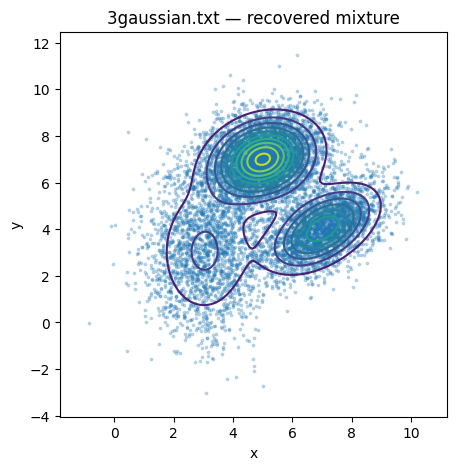

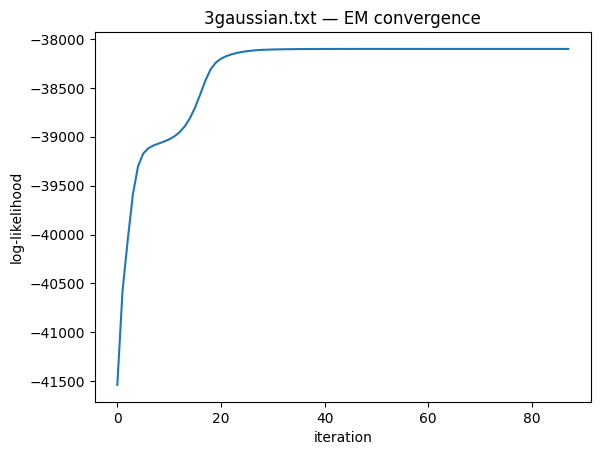

2gaussian: sklearn means =
[[3.03 3.05]
 [7.03 3.99]]
3gaussian: sklearn means =
[[3.03 2.89]
 [7.03 4.03]
 [4.98 6.98]]


In [73]:
plot_gmm_contours(X_3g, means_3g, covs_3g, weights_3g, "3gaussian.txt — recovered mixture")
plt.figure(); plt.plot(ll_3g); plt.xlabel("iteration"); plt.ylabel("log-likelihood")
plt.title("3gaussian.txt — EM convergence"); plt.show()

# library sanity check: sklearn's GaussianMixture, same K, should reach the same means/log-likelihood
for name, X, K in [("2gaussian", X_2g, 2), ("3gaussian", X_3g, 3)]:
    skgmm = GaussianMixture(n_components=K, covariance_type='full', random_state=0).fit(X)   ### TODO_STUDENT ### fit sklearn's GaussianMixture as a library baseline, same K
    print(f"{name}: sklearn means =\n{np.round(skgmm.means_, 2)}")


Compare the true-vs-recovered tables and contour plots above, and sklearn's `GaussianMixture`
means, to your own results, and discuss.


2gaussian.txt. EM recovered the true parameters closely. Both means are within 0.03 of the truth, the weights are 0.335 / 0.665 against the true 0.333 / 0.667, and the covariance errors are small (0.074 and 0.026). The contour plot shows the right shapes: the left cloud is a tall upright oval, because its variance in y is 3 times its variance in x, and the right cloud is tilted, because of its 0.5 correlation. The log-likelihood went up at every step and converged in 38 iterations.

3gaussian.txt. EM again found all three clouds. The means are within 0.05 and the weights within 0.006 of the truth. The one weaker result is the covariance of the cloud at [3, 3] (error 0.388). This cloud is spread out vertically and overlaps with the large cloud at [5, 7], so some points could belong to either one, and that makes its shape harder to pin down. This run needed 87 iterations, and the convergence curve has a flat stretch around iterations 5–12 where the clouds were still rearranging before settling.

Comparison with sklearn. sklearn’s GaussianMixture finds the same clouds, with means close to mine. The small differences, up to about 0.16 on the [3, 3] cloud, come from sklearn’s default stopping rule, which is much looser than mine, so it stops a little earlier, before fully converging. The small remaining errors in my own results come from the sample itself: with a finite number of points, even a perfect algorithm won’t recover the exact true values.

### Part (C) — the ELBO you have been optimizing &nbsp; [10 points, written]

Parts (A)/(B) never mentioned a bound, but one was there the whole time. For **any** distribution
$q(z\mid\mathbf{x})$ over the latent variable,

$$\log p(\mathbf{x}) = \mathbb{E}_{q}\big[\log p(\mathbf{x}\mid z)\big]-\mathrm{KL}\big(q(z\mid\mathbf{x})\,\|\,p(z)\big) \;+\; \mathrm{KL}\big(q(z\mid\mathbf{x})\,\|\,p(z\mid\mathbf{x})\big),$$

where the first two terms are the **ELBO** and the last one is $\ge 0$. You are not asked to derive
this — only to say which of *your own* computed quantities plays each role. The cell below is given
to you: run it, and let the numbers inform your answer.


In [74]:
# The mapping is testable, not just assertable: with q = your responsibilities the bound should
# EQUAL the log-likelihood; with any other q it must come out strictly lower.
def elbo_gmm(X, means, covs, weights, q):
    """ELBO = E_q[log p(x,z)] + H(q), summed over the data. A lower bound on sum_i log p(x_i)."""
    comp = np.stack([multivariate_normal(means[k], covs[k]).logpdf(X) + np.log(weights[k])
                     for k in range(len(weights))], axis=1)       # log p(x_i, z_i=k)
    ell = (q * comp).sum()
    H = -(q * np.log(np.clip(q, 1e-300, None))).sum()
    return ell + H

# q = the responsibilities your E step computes (the exact posterior)
dens_2g = np.stack([weights_2g[k] * multivariate_normal(means_2g[k], covs_2g[k]).pdf(X_2g)
                    for k in range(2)], axis=1)
r_2g = dens_2g / dens_2g.sum(axis=1, keepdims=True)
loglik_2g = np.log(dens_2g.sum(axis=1)).sum()

q_uniform = np.full_like(r_2g, 0.5)                  # a deliberately bad guess, still a valid q
q_prior = np.tile(weights_2g, (len(X_2g), 1))        # another: ignore the data, just use pi_k

print(f"log p(X)                                  = {loglik_2g:12.4f}")
for name, q in [("ELBO with q = responsibilities", r_2g),
                ("ELBO with q = uniform (0.5, 0.5)", q_uniform),
                ("ELBO with q = the prior (pi_k)", q_prior)]:
    e = elbo_gmm(X_2g, means_2g, covs_2g, weights_2g, q)
    print(f"{name:41s} = {e:12.4f}   gap = {loglik_2g - e:9.4f}")


log p(X)                                  =  -21018.6350
ELBO with q = responsibilities            =  -21018.6350   gap =    0.0000
ELBO with q = uniform (0.5, 0.5)          =  -44825.3725   gap = 23806.7375
ELBO with q = the prior (pi_k)            =  -42240.2014   gap = 21221.5664


### Your answer

*Write your answer here.*

**(a)** For your Gaussian mixture, what plays the role of $p(z)$, and what plays the role of
$q(z\mid\mathbf{x}_i)$? Name the variable in your own code for each.

**(b)** Both are lists of $K$ numbers. Say in one sentence what the difference between them is.

**(c)** Look at the gaps printed above. Why is the gap exactly zero for one choice of $q$ and large
for the other two — and what does that tell you about what the E step is actually doing?

(a) p(z) is the mixture weights π_k, the variable weights in my code. q(z | xᵢ) is the responsibilities for point i, row i of r in my code (⟨z_ik⟩ in the notes).

(b) The weights are the same for every point and describe how likely each cloud is before looking at the point. The responsibilities are different for every point, because they update those weights after seeing where xᵢ is, using Bayes’ rule: r_ik ∝ π_k · N(xᵢ; μ_k, Σ_k).

(c) The gap between log p(X) and the ELBO equals the KL divergence between q and the true posterior over z. The responsibilities are the true posterior, so the KL is zero and the gap is exactly 0.0000 (both values are −21018.635). The other two choices of q ignore where each point is: uniform gives every point 50/50, and the prior gives every point 1/3 and 2/3. But almost every point clearly belongs to one cloud, so these guesses are far from the truth, and the gaps are large (23,806.7 for uniform and 21,221.6 for the prior). The prior’s gap is a bit smaller because its 1/3–2/3 split at least matches the overall cloud sizes.

## PROBLEM 4 — EM with a Mixture of Binomials &nbsp; [50 points]

No off-the-shelf library implements a Binomial-mixture EM, so this problem is validated the same
way as Problem 3: generate data from known (p1, p2, π), then check that EM recovers them.

Symbols follow the lecture note (`EM_MIXTURES` §7.1): **n** flips per sequence, **N** sequences,
**K** coins with head-probabilities p_1..p_K and mixture weights π_1..π_K.

**A) Generate the data.**


In [75]:
def generate_coin_flip_data(p1, p2, pi, n=10, N=200, seed=0):
    """Simulate N sequences of n flips from a 2-coin mixture: coin 1 (head-probability p1) is
    chosen with probability pi, coin 2 (head-probability p2) otherwise. Returns the N x n matrix
    of 0/1 outcomes (the coin identity itself is not returned -- EM has to recover it)."""
    rng = np.random.RandomState(seed)
    coin1 = rng.rand(N) < pi                                                  ### TODO_STUDENT ### decide which coin generated each sequence, with probability pi for coin 1
    head_prob = np.where(coin1, p1, p2)
    flips = (rng.rand(N, n) < head_prob[:, None]).astype(int)                                                  ### TODO_STUDENT ### simulate n flips of the chosen coin, for every sequence at once
    return flips

flips_demo = generate_coin_flip_data(p1=0.75, p2=0.4, pi=0.8, n=10, N=5, seed=0)
print("example generated sequences (rows = sequences, columns = the n=10 flips):")
print(flips_demo)


example generated sequences (rows = sequences, columns = the n=10 flips):
[[1 1 0 0 1 0 1 1 0 1]
 [1 1 0 0 0 0 0 1 0 1]
 [1 1 0 1 1 1 0 1 1 1]
 [1 1 1 0 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 0 1 1]]


**B) Recover the parameters.**

In [76]:
def binomial_mixture_em(flips, n_components=2, max_iter=300, tol=1e-8, seed=0):
    """From-scratch EM for a mixture of Binomial(n, p_k) components -- one scalar
    head-probability per coin, shared across all n flips in a sequence (not a separate parameter
    per flip position: within one sequence every flip comes from the same coin)."""
    rng = np.random.RandomState(seed)
    N, n = flips.shape
    heads = flips.sum(axis=1)          # sufficient statistic per sequence
    p = rng.uniform(0.2, 0.8, n_components)
    weights = np.full(n_components, 1.0 / n_components)
    loglik_hist = []

    for it in range(max_iter):
        # E-step. The shared C(n, heads_i) binomial-coefficient factor cancels in the
        # responsibility ratio, so it's dropped here -- and is never added back, including in
        # loglik_hist below. That's fine for parameter estimation (it's a per-sequence additive
        # constant, identical across components and iterations, so it affects neither
        # responsibilities nor convergence) but means loglik_hist is the mixture log-density up
        # to that missing constant, not the true observed-data log-likelihood -- only the
        # convergence *plot*'s absolute y-axis scale is affected.
        log_lik = heads[:, None] * np.log(p)[None, :] + (n - heads)[:, None] * np.log(1 - p)[None, :]   ### TODO_STUDENT ### per-sequence, per-coin Binomial log-likelihood (up to the shared C(n,heads) factor)
        m = log_lik.max(axis=1, keepdims=True)
        unnorm = weights[None, :] * np.exp(log_lik - m)
        total = unnorm.sum(axis=1, keepdims=True)
        r = unnorm / total                                            ### TODO_STUDENT ### normalize into responsibilities (the note's <z_ik>) over the n_components coins
        loglik_hist.append(float(np.sum(np.log(total) + m)))
        if it > 0 and abs(loglik_hist[-1] - loglik_hist[-2]) < tol:
            break

        # M-step
        Nk = r.sum(axis=0)
        weights = Nk / N                                              ### TODO_STUDENT ### update mixture weights pi_k = N_k / N
        p = (r * heads[:, None]).sum(axis=0) / (n * Nk)                                ### TODO_STUDENT ### update each coin's head-probability p_k = S_k / (n * R_k): responsibility-weighted fraction of heads

    return p, weights, loglik_hist


In [77]:
# Try several (p1, p2, pi) settings; match recovered coins to the true ones by sorting on head
# probability (with only two components, sorting both true and estimated pairs ascending is an
# easy, unambiguous match -- and keeps the "weights" columns aligned with the "(p1, p2)" columns).
# The last setting is deliberately overlapping: see EM_MIXTURES section 8 on weak identifiability.
settings = [(0.75, 0.4, 0.8), (0.9, 0.1, 0.3), (0.6, 0.5, 0.5)]
rows = []
for p1_true, p2_true, pi_true in settings:
    flips = generate_coin_flip_data(p1_true, p2_true, pi_true, n=10, N=300, seed=1)
    p_est, w_est, ll = binomial_mixture_em(flips, n_components=2, seed=0)

    true_p, true_w = np.array([p1_true, p2_true]), np.array([pi_true, 1 - pi_true])
    true_order, est_order = np.argsort(true_p), np.argsort(p_est)
    rows.append({
        "true (p1, p2)": tuple(true_p[true_order].round(3)),
        "est (p1, p2)": tuple(p_est[est_order].round(3)),
        "true weights": tuple(true_w[true_order].round(3)),
        "est weights": tuple(w_est[est_order].round(3)),
        "iterations": len(ll),
    })

binomial_em_results = pd.DataFrame(rows)
binomial_em_results


,"true (p1, p2)","est (p1, p2)",true weights,est weights,iterations
0,"(0.4, 0.75)","(0.468, 0.741)","(0.2, 0.8)","(0.239, 0.761)",216
1,"(0.1, 0.9)","(0.097, 0.894)","(0.7, 0.3)","(0.703, 0.297)",7
2,"(0.5, 0.6)","(0.496, 0.582)","(0.5, 0.5)","(0.459, 0.541)",300


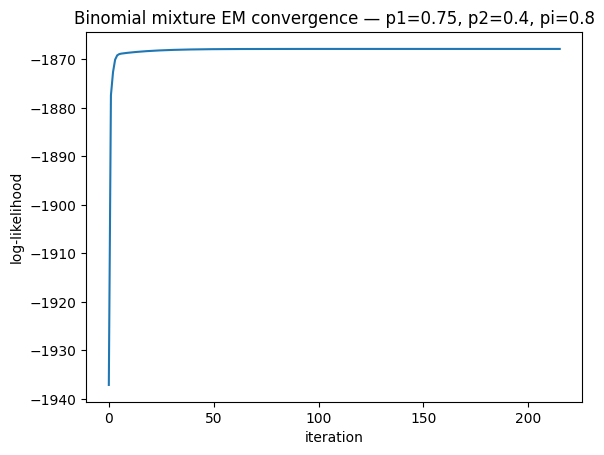

In [78]:
# convergence plot for the first setting above
flips = generate_coin_flip_data(*settings[0], n=10, N=300, seed=1)
_, _, ll = binomial_mixture_em(flips, n_components=2, seed=0)
plt.figure(); plt.plot(ll); plt.xlabel("iteration"); plt.ylabel("log-likelihood")
plt.title(f"Binomial mixture EM convergence — p1={settings[0][0]}, p2={settings[0][1]}, pi={settings[0][2]}")
plt.show()


Compare the recovered (p1, p2) and π to the true generating values above, and discuss. Look at the
`iterations` column too: one of the three settings is deliberately overlapping (p1=0.6 vs p2=0.5),
and it behaves very differently from the well-separated ones. Say what happens and why -- the
answer is about the data, not the optimizer. See `EM_MIXTURES` §8.

**[optional extension, no credit] C) K coins instead of two.** `binomial_mixture_em` already
takes `n_components` as a parameter, so generalizing to K coins is a one-line change -- a quick
demonstration with K=3:


Well-separated coins (setting 2). EM recovered everything almost exactly, with every value within 0.006, in only 7 iterations. A 0.1 coin gives about 1 head in 10 flips and a 0.9 coin about 9, so almost every row clearly belongs to one coin. The responsibilities are close to 0 or 1 from the start, and EM settles quickly.

Moderately separated coins (setting 1). The 0.75 coin was recovered well (0.741), but the 0.4 coin came out at 0.468 and its weight at 0.239 instead of 0.2. The 0.4 coin produced only about 60 of the 300 rows, so there is less data about it. Rows with 5 or 6 heads could also come from either coin. EM jumped close to the answer in the first few iterations, then spent about 200 more slowly adjusting how to split those unclear rows.

Overlapping coins (setting 3). This setting behaves very differently. EM used all 300 iterations and never met the stopping rule. The p values look close to the truth, but the weights are off. The real problem is the data, not EM: ten flips of a 0.6 coin and of a 0.5 coin give very similar results, about 6 heads vs. 5. Many different combinations of (p₁, p₂, π) explain the data almost equally well, so the log-likelihood is nearly flat around the answer. EM keeps making tiny improvements but has no clear peak to climb toward. Running more iterations or trying more random restarts wouldn’t fix this. Only more information would help, such as more flips per sequence or more sequences.

In [79]:
p_true_K = [0.85, 0.5, 0.15]
w_true_K = [0.3, 0.4, 0.3]
flips_K = np.zeros((300, 10), dtype=int)
rng = np.random.RandomState(2)
coin_idx = rng.choice(3, size=300, p=w_true_K)
for i, k in enumerate(coin_idx):
    flips_K[i] = rng.binomial(1, p_true_K[k], size=10)

p_est_K, w_est_K, _ = binomial_mixture_em(flips_K, n_components=3, seed=0)
order_K = np.argsort(p_est_K)
print("true p (sorted): ", np.round(sorted(p_true_K), 3))
print("est  p (sorted): ", np.round(p_est_K[order_K], 3))


true p (sorted):  [0.15 0.5  0.85]
est  p (sorted):  [0.137 0.444 0.846]


## PROBLEM 5 — Bayesian Linear Regression: Ridge as MAP &nbsp; [60 points]

Bridges back to HW1's closed-form Ridge regression. Model: y = wᵀx + ε, ε ~ N(0, σ²), with a
Gaussian prior w ~ N(0, τ²I). Throughout, `X_train_housing` / `X_test_housing` are already
standardized (unit variance, zero training mean) and `y` is centered by its training mean — the
centering half of that is the same trick sklearn's own `Ridge(fit_intercept=True)` uses internally
to avoid needing to special-case an unpenalized intercept term (the standardizing half is an extra
step we take on top, so one isotropic prior variance τ² is sensible across features of very
different scales). See `../lecture_notes/bayesian_ridge_regression.pdf` for the full derivation.

Parts A and B below are required. Part C (further down) is optional, no credit.


In [80]:
# ---- Housing (regression), pre-split train/test files, standardized like HW1 ----
train_housing = np.loadtxt(f"{DATA}/housing_train.txt")
test_housing = np.loadtxt(f"{DATA}/housing_test.txt")
X_train_housing, y_train_housing = train_housing[:, :-1], train_housing[:, -1]
X_test_housing, y_test_housing = test_housing[:, :-1], test_housing[:, -1]

housing_scaler = StandardScaler().fit(X_train_housing)
X_train_housing = housing_scaler.transform(X_train_housing)
X_test_housing = housing_scaler.transform(X_test_housing)

y_train_mean = y_train_housing.mean()
yc_train_housing = y_train_housing - y_train_mean   # centered target -- removes the need for a bias term

print("Housing train:", X_train_housing.shape, " test:", X_test_housing.shape)


Housing train: (433, 13)  test: (74, 13)


**A) MAP = Ridge.** Posterior mean (the MAP estimate) vs. sklearn's `Ridge`, at a fixed λ.

In [81]:
def bayesian_ridge_posterior(X, y_centered, sigma2, lam):
    """Closed-form Gaussian posterior N(mean_w, cov_w) over the (centered-data) regression
    weights: precision A = (1/sigma2) X^T X + (1/tau2) I, with lam = sigma2/tau2."""
    A = X.T @ X + lam * np.eye(X.shape[1])                                                ### TODO_STUDENT ### posterior precision (up to the 1/sigma2 factor): X^T X + lambda*I
    cov_w = sigma2 * np.linalg.inv(A)                          ### TODO_STUDENT ### posterior covariance Sigma_w = sigma2 * (X^T X + lambda I)^-1
    mean_w = np.linalg.solve(A, X.T @ y_centered)                                  ### TODO_STUDENT ### posterior mean mu_w -- identical to the Ridge solution at this lambda
    return mean_w, cov_w


lam_check = 5.0
sk_ridge_check = Ridge(alpha=lam_check, fit_intercept=True).fit(X_train_housing, y_train_housing)  ### TODO_STUDENT ### fit sklearn's Ridge as a library check for Part A's "MAP = Ridge" claim
mean_w_check, _ = bayesian_ridge_posterior(X_train_housing, yc_train_housing, sigma2=1.0, lam=lam_check)

print(f"lambda = {lam_check}")
print("max |sklearn Ridge coef - posterior mean (MAP)| =",
      np.max(np.abs(sk_ridge_check.coef_ - mean_w_check)))
print("sklearn intercept:", round(sk_ridge_check.intercept_, 4),
      " vs. training-set y-mean:", round(y_train_mean, 4))


lambda = 5.0
max |sklearn Ridge coef - posterior mean (MAP)| = 6.88338275267597e-14
sklearn intercept: 22.8672  vs. training-set y-mean: 22.8672


**B) The full posterior, not just its mode.** Predictive distribution at each test point:
mean from the posterior mean, variance = leftover noise σ² plus the model's own parameter
uncertainty xᵀΣ_w x.


In [82]:
def predictive_distribution(X, mean_w, cov_w, sigma2):
    pred_mean = X @ mean_w
    pred_var = sigma2 + np.einsum('ij,jk,ik->i', X, cov_w, X)  ### TODO_STUDENT ### predictive variance = leftover noise sigma2 + parameter uncertainty x^T Sigma_w x
    return pred_mean, pred_var


# sigma^2: a plug-in estimate from the (unregularized) least-squares residual variance on
# the training data, held fixed while lambda varies below
w_ols, *_ = np.linalg.lstsq(X_train_housing, yc_train_housing, rcond=None)
sigma2_hat = np.var(yc_train_housing - X_train_housing @ w_ols)
print(f"sigma^2 (from OLS residual variance): {sigma2_hat:.3f}")

lam_demo = 5.0   # revisited properly via the evidence in the optional Part C below
mean_w, cov_w = bayesian_ridge_posterior(X_train_housing, yc_train_housing, sigma2_hat, lam_demo)
pred_mean, pred_var = predictive_distribution(X_test_housing, mean_w, cov_w, sigma2_hat)
pred_mean = pred_mean + y_train_mean            # back into original Housing-price units
pred_std = np.sqrt(pred_var)

lower, upper = pred_mean - 1.96 * pred_std, pred_mean + 1.96 * pred_std
coverage = np.mean((y_test_housing >= lower) & (y_test_housing <= upper))
print(f"95% predictive-interval empirical coverage on the Housing test set: {coverage:.3f}")


sigma^2 (from OLS residual variance): 22.081
95% predictive-interval empirical coverage on the Housing test set: 0.946


**[optional, no credit] C) Choosing λ without touching a validation set.** The evidence
log p(y|X) integrates w out entirely: y ~ N(0, C) with C = σ²I + τ²XXᵀ (a sum of two independent
zero-mean Gaussians, Xw ~ N(0, τ²XXᵀ) and ε ~ N(0, σ²I)). Sweep λ, and compare the
evidence-maximizing λ to the λ that k-fold cross validation on the *training* data would pick --
not a single held-out test split, which turns out to be a surprisingly unreliable comparison
target (see the lecture note for the full worked-through example).


In [83]:
def log_evidence(X, y_centered, sigma2, lam):
    n = X.shape[0]
    tau2 = sigma2 / lam
    C = sigma2 * np.eye(n) + tau2 * X @ X.T                                                       ### TODO_STUDENT ### marginal covariance of y after integrating out w: sigma2*I + tau2*X X^T
    sign, logdet = np.linalg.slogdet(C)
    quad = y_centered @ np.linalg.solve(C, y_centered)                              ### TODO_STUDENT ### the quadratic form y^T C^-1 y (solved, not explicitly inverted)
    return -0.5 * (quad + logdet + n * np.log(2 * np.pi))


def kfold_cv_mse(X, y_centered, lam, k=10, seed=0):
    """Mean held-out MSE for one lambda, k-fold cross-validated *within the training set*
    (never touches the real test set) -- the standard, statistically sound way to estimate
    generalization error, unlike a single small held-out split."""
    kf = KFold(n_splits=k, shuffle=True, random_state=seed)
    fold_mses = []
    for tr_idx, val_idx in kf.split(X):
        mean_w_fold, _ = bayesian_ridge_posterior(X[tr_idx], y_centered[tr_idx], sigma2_hat, lam)
        fold_mses.append(np.mean((y_centered[val_idx] - X[val_idx] @ mean_w_fold) ** 2))
    return np.mean(fold_mses)


lambdas = np.logspace(-2, 3, 40)   # same range as HW1's Ridge regularization-path sweep
evidences = [log_evidence(X_train_housing, yc_train_housing, sigma2_hat, lam) for lam in lambdas]
lam_evidence = lambdas[np.argmax(evidences)]

cv_mses = [kfold_cv_mse(X_train_housing, yc_train_housing, lam) for lam in lambdas]
lam_cv = lambdas[np.argmin(cv_mses)]

test_mses = []
for lam in lambdas:
    mean_w_l, _ = bayesian_ridge_posterior(X_train_housing, yc_train_housing, sigma2_hat, lam)
    pred_l = X_test_housing @ mean_w_l + y_train_mean
    test_mses.append(np.mean((y_test_housing - pred_l) ** 2))
lam_test_best = lambdas[np.argmin(test_mses)]

# library check: sklearn's BayesianRidge runs the real thing -- joint type-II ML / MacKay's
# "evidence procedure" over BOTH sigma2 and tau2 (we only swept lambda at a fixed, plug-in
# sigma2) -- if your from-scratch evidence sweep is correct, its argmax should land close to
# sklearn's independently-optimized answer
sk_bayes_ridge = BayesianRidge(fit_intercept=True).fit(X_train_housing, y_train_housing)  ### TODO_STUDENT ### fit sklearn's BayesianRidge as a library check for the evidence-based lambda
lam_sklearn = sk_bayes_ridge.lambda_ / sk_bayes_ridge.alpha_   # sklearn's (weight precision)/(noise precision) = our sigma2/tau2 = lambda

print(f"lambda maximizing the evidence (from-scratch, plug-in sigma2, no held-out data used): {lam_evidence:.3g}")
print(f"lambda implied by sklearn's BayesianRidge (joint evidence maximization):              {lam_sklearn:.3g}")
print(f"lambda minimizing 10-fold CV MSE (training data only, the fair comparison):           {lam_cv:.3g}")
print(f"lambda minimizing the single 74-point test-split MSE (kept for contrast -- see below): {lam_test_best:.3g}")


lambda maximizing the evidence (from-scratch, plug-in sigma2, no held-out data used): 4.92
lambda implied by sklearn's BayesianRidge (joint evidence maximization):              5.03
lambda minimizing 10-fold CV MSE (training data only, the fair comparison):           3.67
lambda minimizing the single 74-point test-split MSE (kept for contrast -- see below): 412


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2349: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2349: RuntimeWarning: overflow encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2349: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)


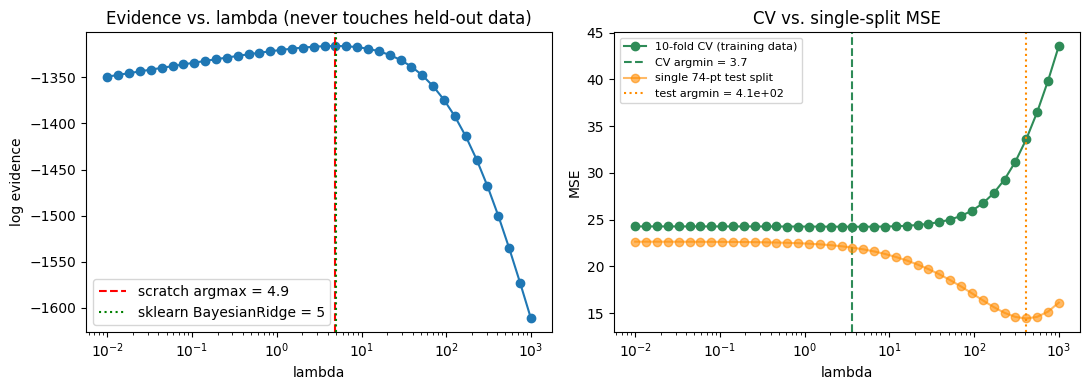

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(lambdas, evidences, "o-")
axes[0].axvline(lam_evidence, color="r", linestyle="--", label=f"scratch argmax = {lam_evidence:.2g}")
axes[0].axvline(lam_sklearn, color="g", linestyle=":", label=f"sklearn BayesianRidge = {lam_sklearn:.2g}")
axes[0].set_xscale("log"); axes[0].set_xlabel("lambda"); axes[0].set_ylabel("log evidence")
axes[0].set_title("Evidence vs. lambda (never touches held-out data)"); axes[0].legend()

axes[1].plot(lambdas, cv_mses, "o-", color="seagreen", label="10-fold CV (training data)")
axes[1].axvline(lam_cv, color="seagreen", linestyle="--", label=f"CV argmin = {lam_cv:.2g}")
axes[1].plot(lambdas, test_mses, "o-", color="darkorange", alpha=0.6, label="single 74-pt test split")
axes[1].axvline(lam_test_best, color="darkorange", linestyle=":", label=f"test argmin = {lam_test_best:.2g}")
axes[1].set_xscale("log"); axes[1].set_xlabel("lambda"); axes[1].set_ylabel("MSE")
axes[1].set_title("CV vs. single-split MSE"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


Discuss: do the evidence-based and cross-validated λ choices land in the same region? How about
the single test-split argmin? What do you gain (and what do you give up) by picking λ from the
evidence instead of cross-validating -- note it never touches a validation fold, or the test set,
at all.


The evidence-based λ (4.92) and the 10-fold CV λ (3.67) land in the same region. sklearn’s BayesianRidge, which optimizes σ² and τ² jointly, gives 5.03, which confirms the from-scratch evidence sweep. The single 74-point test split picks λ = 412, which is far away. In the plot, the CV curve is almost flat between λ = 0.01 and λ ≈ 10, so any λ in that range performs about the same, while the test-split curve keeps dropping until λ ≈ 400. With only 74 points, one test split is too noisy to choose λ from: a few unusual houses can pull its minimum far from where the model actually generalizes best.

Choosing λ from the evidence uses only the training data, needs no validation folds, and costs a single computation per λ instead of 10 model fits. What you give up is that it trusts the model’s assumptions (Gaussian noise, Gaussian prior). If those are wrong, the evidence can point to the wrong λ, while cross-validation measures prediction error directly and doesn’t depend on those assumptions.

## PROBLEM 6 (THEORY) — Is the EM Log-Likelihood Allowed to Decrease? &nbsp; [25 points]

> **Depends on Problem 3.** These cells reuse `ll_2g`, `ll_3g` (the per-iteration log-likelihood
> histories your `gaussian_mixture_em` returns) and `X_2g`. **Finish Problem 3 first** — nothing below
> will run until it works.

**The question.** You are monitoring EM and the observed-data log-likelihood drops from one iteration
to the next. Is that acceptable behaviour, or does it indicate a problem? Identify at least one
concrete, specific bug that could cause it, and say where in the algorithm you would look.

**How this section works.** Three experiments are set up for you. You fill in the two sabotage lines
(marked `TODO_STUDENT`), run everything, and then write your answer in the cell at the end. Predict
what each experiment will do *before* you run it — one of them does not do what you expect.


**Experiment 1 — check the correct implementation numerically, rather than by eye.**

In [42]:
for name, ll in [("2gaussian", ll_2g), ("3gaussian", ll_3g)]:
    steps = np.diff(ll)
    print(f"{name}: {len(ll)} iterations, smallest step = {steps.min():+.3e}, "
          f"decreases = {(steps < -1e-9).sum()}")


2gaussian: 38 iterations, smallest step = +5.508e-07, decreases = 0
3gaussian: 88 iterations, smallest step = +9.489e-07, decreases = 0


**Experiment 2 — break the E step on purpose.** The responsibilities come out near 0/1 anyway, so why
not just round them? Below is Problem 3's EM with one line sabotaged, still reporting the correct
(soft) log-likelihood. **Fill in the hard-assignment line.**


In [85]:
def em_bug_hard_assign(X, K, max_iter=60, seed=0):
    """Problem 3's EM, with the E step rounding responsibilities to 0/1.
    Everything else -- including the reported log-likelihood -- is unchanged."""
    rng = np.random.RandomState(seed)
    n, d = X.shape
    means = X[rng.choice(n, K, replace=False)].copy()
    covs = [np.cov(X.T) for _ in range(K)]
    weights = np.full(K, 1.0 / K)
    loglik_hist = []

    for it in range(max_iter):
        dens = np.stack([weights[k] * multivariate_normal(means[k], covs[k]).pdf(X)
                         for k in range(K)], axis=1)
        total = dens.sum(axis=1, keepdims=True)
        loglik_hist.append(np.sum(np.log(total)))     # the CORRECT observed-data log-likelihood
        r = dens / total
        r = np.eye(K)[r.argmax(axis=1)]              ### TODO_STUDENT ### THE BUG: replace the soft responsibilities with a hard 0/1 assignment to the most likely component

        Nk = r.sum(axis=0)
        weights = Nk / n
        means = (r.T @ X) / Nk[:, None]
        for k in range(K):
            diff = X - means[k]
            covs[k] = (r[:, k:k+1] * diff).T @ diff / Nk[k] + 1e-6 * np.eye(d)
    return np.array(loglik_hist)

ll_hard = em_bug_hard_assign(X_2g, K=2, seed=0)
steps_hard = np.diff(ll_hard)
n_dip = (steps_hard < -1e-9).sum()
print(f"hard-assignment run: {n_dip} decreases, worst step = {steps_hard.min():+.3f}")
if n_dip:
    i = int(np.argmax(steps_hard < -1e-9))
    print(f"first dip at iteration {i}: {ll_hard[i]:.2f} -> {ll_hard[i+1]:.2f}")


hard-assignment run: 6 decreases, worst step = -0.822
first dip at iteration 11: -21023.05 -> -21023.88


**Experiment 3 — break the M step, and predict the result first.** A classic suspect: computing the
covariance from the *previous* iteration's means instead of the ones just updated. **Fill in the
stale-mean line.** Write down what you expect to happen before running it.


In [86]:
def em_bug_stale_mean(X, K, max_iter=60, seed=0):
    """Problem 3's EM, with the covariance update using the PREVIOUS iteration's means."""
    rng = np.random.RandomState(seed)
    n, d = X.shape
    means = X[rng.choice(n, K, replace=False)].copy()
    covs = [np.cov(X.T) for _ in range(K)]
    weights = np.full(K, 1.0 / K)
    loglik_hist = []

    for it in range(max_iter):
        dens = np.stack([weights[k] * multivariate_normal(means[k], covs[k]).pdf(X)
                         for k in range(K)], axis=1)
        total = dens.sum(axis=1, keepdims=True)
        loglik_hist.append(np.sum(np.log(total)))
        r = dens / total

        Nk = r.sum(axis=0)
        weights = Nk / n
        means_old = means.copy()
        means = (r.T @ X) / Nk[:, None]
        mu_for_cov = means_old                                ### TODO_STUDENT ### THE BUG: center the covariance on the PREVIOUS means rather than the ones just computed
        for k in range(K):
            diff = X - mu_for_cov[k]
            covs[k] = (r[:, k:k+1] * diff).T @ diff / Nk[k] + 1e-6 * np.eye(d)
    return np.array(loglik_hist)

ll_stale = em_bug_stale_mean(X_2g, K=2, seed=0)
steps_stale = np.diff(ll_stale)
print(f"stale-mean run: {(steps_stale < -1e-9).sum()} decreases, "
      f"worst step = {steps_stale.min():+.3e}")
print(f"final log-likelihood -- correct: {ll_2g[-1]:.2f}, stale-mean: {ll_stale[-1]:.2f}")


stale-mean run: 0 decreases, worst step = -3.638e-11
final log-likelihood -- correct: -21018.63, stale-mean: -21018.63


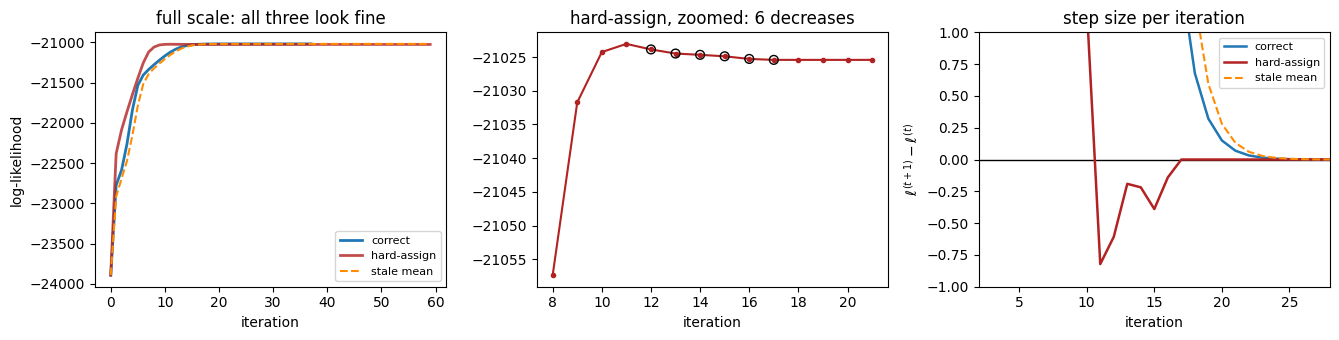

In [87]:
# At full scale the dips are invisible (-0.8 against a range of 3000) -- which is exactly why
# step 1 tested them numerically. Panels 2 and 3 zoom in.
dips = np.where(np.diff(ll_hard) < -1e-9)[0] + 1
lo, hi = max(0, dips.min() - 4), min(len(ll_hard), dips.max() + 5)

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.5))
ax[0].plot(ll_2g, lw=2); ax[0].plot(ll_hard, lw=2, color="firebrick", alpha=.8)
ax[0].plot(ll_stale, lw=1.5, color="darkorange", ls="--")
ax[0].set_title("full scale: all three look fine"); ax[0].set_xlabel("iteration")
ax[0].set_ylabel("log-likelihood"); ax[0].legend(["correct", "hard-assign", "stale mean"], fontsize=8)

ax[1].plot(range(lo, hi), ll_hard[lo:hi], "-o", ms=3, lw=1.5, color="firebrick")
ax[1].scatter(dips, ll_hard[dips], s=40, facecolor="none", edgecolor="k", zorder=5)
ax[1].set_title(f"hard-assign, zoomed: {len(dips)} decreases"); ax[1].set_xlabel("iteration")

ax[2].axhline(0, color="k", lw=1)
ax[2].plot(np.diff(ll_2g), lw=1.8, label="correct")
ax[2].plot(np.diff(ll_hard), lw=1.8, color="firebrick", label="hard-assign")
ax[2].plot(np.diff(ll_stale), lw=1.5, color="darkorange", ls="--", label="stale mean")
ax[2].set_ylim(-1.0, 1.0); ax[2].set_xlim(lo - 6, hi + 6)
ax[2].set_title("step size per iteration"); ax[2].set_xlabel("iteration")
ax[2].set_ylabel(r"$\ell^{(t+1)}-\ell^{(t)}$"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()


### Your answer

*Write your answer here. Cover all three parts.*

**(a)** Is a decrease acceptable behaviour, or a bug? State the guarantee EM gives, what it does
**not** guarantee, and the one kind of decrease that is genuinely harmless.

(a) No, a real decrease means something is wrong. EM promises that the log-likelihood never goes down. The E-step makes the ELBO equal to the log-likelihood, and the M-step then raises the ELBO, so the log-likelihood can only go up or stay the same. EM does not promise the best answer, though. It can get stuck in a local maximum or crawl along a flat region. The only decrease that’s fine is a tiny one from floating-point rounding near the end, like the −3.6e-11 step in Experiment 3.

**(b)** Name one concrete, specific bug that causes a decrease, and say where you would look for it
(E step, M step, or how you are reporting). Use your Experiment 2 numbers as evidence.

(b) One bug that causes this is rounding the responsibilities to 0 or 1 in the E-step. Once they’re rounded, they’re no longer the true posterior, so EM’s guarantee doesn’t hold anymore. In my run, the log-likelihood went down 6 times. The worst drop was −0.822, and the first came at iteration 11 (−21023.05 → −21023.88). It also finished at about −21025.5, worse than correct EM’s −21018.63. If I saw a decrease, I would check the E-step first, then the M-step formulas, then how the log-likelihood is being computed.

**(c)** Experiment 3 is a genuine coding error, yet look at what it did to the curve and to the final
log-likelihood. Explain *why* it behaves that way — and say what that implies about using a monotone
likelihood plot as your check that an EM implementation is correct.

(c) Using the old means for the covariance is a real bug, but the curve never went down and it reached exactly the same final value (−21018.63). Using the old means only makes each covariance a little too wide, so the update still improves the fit. And as EM converges, the means stop changing, so old and new means become the same and the bug disappears. This shows that a curve that never goes down doesn’t prove the code is correct. A decrease means there’s definitely a bug, but no decrease doesn’t mean there isn’t one. To really check, compare the results to the true parameters or to sklearn.


## PROBLEM 7 (THEORY) — Naive Bayes: Choosing the Right Likelihood Family &nbsp; [25 points]

> **Depends on Problem 2.** These cells reuse `bernoulli_nb_fit`, `gaussian_nb_fit` and their
> `*_log_odds` scorers, plus the `Xtr/Xte/ytr/yte` split.

**The question.** Suppose every Spambase feature were strictly binary (presence/absence of a word), and
you fit a *Gaussian* per feature per class anyway. Explain what "Naive Bayes" actually assumes — as
opposed to what it says nothing about — and why fitting a Gaussian to strictly binary data is the wrong
choice **even though the independence assumption is identical either way**.

**How this section works.** Three measurements are set up for you; you fill in two computations, then
answer in the cell at the end. The last measurement does not come out the way the question implies —
part (c) asks you to account for that.


**Measurement 1 — where does a Gaussian fitted to a binary feature put its probability?**
For a binary feature, a Bernoulli forces $\mu=p$ and $\sigma^2=p(1-p)$; fit a Gaussian with those
moments and ask how much of its mass lands on values the feature can never take.


In [88]:
from scipy.stats import norm

# --- (1) How much of the fitted Gaussian's mass sits on values the feature cannot take?
p_grid = np.array([0.1, 0.3, 0.5, 0.7, 0.9])
sd = np.sqrt(p_grid * (1 - p_grid))
impossible = norm.cdf(0, loc=p_grid, scale=sd) + norm.sf(1, loc=p_grid, scale=sd)  ### TODO_STUDENT ### total probability the fitted Gaussian N(p, p(1-p)) puts on values below 0 or above 1 -- outcomes a binary feature cannot take
tbl = pd.DataFrame({
    "p = P(x=1|c)": p_grid,
    "fitted mu": p_grid,
    "fitted var = p(1-p)": (p_grid * (1 - p_grid)).round(4),
    "impossible mass": impossible.round(4),
})
print(tbl.to_string(index=False))
print("\n(A Bernoulli places 100% of its mass exactly on {0, 1}.)")


 p = P(x=1|c)  fitted mu  fitted var = p(1-p)  impossible mass
          0.1        0.1                 0.09           0.3708
          0.3        0.3                 0.21           0.3197
          0.5        0.5                 0.25           0.3173
          0.7        0.7                 0.21           0.3197
          0.9        0.9                 0.09           0.3708

(A Bernoulli places 100% of its mass exactly on {0, 1}.)


**Measurement 2 — are zero-variance features a real problem, or a corner case?**

In [89]:
# --- (4) Zero-variance features are real, under the presence/absence encoding P7 describes.
Xtr_pa, Xte_pa = (Xtr > 0).astype(float), (Xte > 0).astype(float)   # "does the word appear at all"
for c in (0, 1):
    n_zero = int((Xtr_pa[ytr == c].var(axis=0) == 0).sum())                                        ### TODO_STUDENT ### how many features never vary within this class -- exactly where a Gaussian's variance is 0 and its density undefined
    print(f"class {c}: {n_zero} of {Xtr_pa.shape[1]} features have ZERO within-class variance "
          f"-> Gaussian density undefined without a floor")


class 0: 3 of 57 features have ZERO within-class variance -> Gaussian density undefined without a floor
class 1: 3 of 57 features have ZERO within-class variance -> Gaussian density undefined without a floor


In [90]:
# --- (3) Same binary features, same independence assumption, two per-feature families.
rows = []
for name, (fit_fn, score_fn) in [("Bernoulli", (bernoulli_nb_fit, bernoulli_nb_log_odds)),
                                 ("Gaussian", (gaussian_nb_fit, gaussian_nb_log_odds))]:
    model = fit_fn(Xtr_pa, ytr)
    s = score_fn(Xte_pa, model)
    fpr, tpr, _ = roc_curve(yte, s)
    rows.append({"family": name,
                 "test accuracy": accuracy_score(yte, (s > 0).astype(int)),
                 "AUC": auc(fpr, tpr),
                 "median |log-odds|": np.median(np.abs(s))})
print(pd.DataFrame(rows).round(4).to_string(index=False))

   family  test accuracy    AUC  median |log-odds|
Bernoulli         0.8762 0.9496            10.4578
 Gaussian         0.8806 0.9517            56.3783


**Measurement 3 — the empirical cost.** Identical binary data, identical independence assumption, two
different per-feature families. Anything that differs is the cost of the family and nothing else.


In [91]:
def match_components(est_means, true_means):
    """EM's component labels are arbitrary -- greedily match each estimated mean to its
    nearest not-yet-used true mean so recovered and true parameters line up for comparison."""
    remaining = list(range(len(true_means)))
    order = []
    for m in est_means:
        dists = [np.linalg.norm(m - true_means[j]) for j in remaining]
        best = remaining.pop(int(np.argmin(dists)))
        order.append(best)
    return order


def compare_to_truth(means, covs, weights, true_means, true_covs, true_weights):
    order = match_components(means, true_means)
    rows = []
    for est_idx, true_idx in enumerate(order):
        rows.append({
            "component": true_idx,
            "true_mean": np.round(true_means[true_idx], 2).tolist(),
            "est_mean": np.round(means[est_idx], 2).tolist(),
            "mean_abs_diff": round(float(np.abs(means[est_idx] - true_means[true_idx]).mean()), 3),
            "true_weight": round(true_weights[true_idx], 3),
            "est_weight": round(float(weights[est_idx]), 3),
            "cov_frob_diff": round(float(np.linalg.norm(covs[est_idx] - true_covs[true_idx])), 3),
        })
    return pd.DataFrame(rows).set_index("component").sort_index()


def plot_gmm_contours(X, means, covs, weights, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 150), np.linspace(y_min, y_max, 150))
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    density = sum(w * multivariate_normal(m, c).pdf(grid) for w, m, c in zip(weights, means, covs))
    plt.figure(figsize=(5, 5))
    plt.scatter(X[:, 0], X[:, 1], s=3, alpha=0.25)
    plt.contour(xx, yy, density.reshape(xx.shape), levels=10)
    plt.title(title); plt.xlabel("x"); plt.ylabel("y")
    plt.show()


### Your answer

*Write your answer here. Cover all three parts.*

**(a)** What does Naive Bayes assume, and what does it leave entirely open? Be precise about which of
the two is responsible for the method's tractability.

(a) Naive Bayes only assumes that the features are independent once you know the class. It doesn’t say what shape each feature’s distribution should be; that’s a separate choice. The independence assumption is what makes it practical: you learn 57 small one-feature models instead of one huge model of all features together.

**(b)** Why is a Gaussian the wrong family for a strictly binary feature? Give at least two distinct
reasons and back each with a number from Measurement 1 or 2.

(b) For binary features the independence assumption is the same either way, so the only question is the shape. A Bernoulli is the exact right fit for 0/1 data. A Gaussian is wrong for two reasons:

1 .It puts probability on impossible values: about 32–37% of its mass falls below 0 or above 1 (31.7% at p = 0.5, 37.1% at p = 0.1 or 0.9).
2. It breaks on features that never change within a class. 3 of the 57 features in each class have zero variance, so for those the Gaussian density can’t be computed and only works because of the small variance floor. A Bernoulli handles them fine.

**(c)** Look at the AUC column in Measurement 3. The Gaussian is **not** worse at ranking. Reconcile
that with your answer to (b): what did the wrong family actually cost, and what does that tell you
about using accuracy as evidence that a model is correct?

(c) Surprisingly, the Gaussian does about as well as the Bernoulli: accuracy 0.881 vs. 0.876 and AUC 0.952 vs. 0.950. It still ranks emails in roughly the right order, because spam-like features still push its score up. The damage is in its confidence. Its median |log-odds| is 56.4 vs. 10.5 for the Bernoulli, meaning it claims odds of about 10²⁴ to 1 on a typical email. Those probabilities are meaningless, so you couldn’t use them to set a threshold like τ in Problem 2. So good accuracy or AUC doesn’t prove a model is right. The model can sort emails well while being badly wrong about how sure it should be.